# 03 — Thèmes exploratoires et liens avec les lieux

**Objectif :** construire une première analyse reproductible TF-IDF + NMF, lire les documents représentatifs et comparer les profils par lieu.

Avec 33 textes d'un mois, les thèmes sont exploratoires. Les numéros n'ont pas de sens intrinsèque ; les groupes doivent être nommés après lecture. Chaque notebook est autonome : celui-ci recharge les données et les annotations éventuelles.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "telecharger_discours.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dossier du projet.")
CORPUS = ROOT / "corpus_francois" / "corpus_nlp.jsonl"
if not CORPUS.exists():
    raise FileNotFoundError("Exécuter telecharger_discours.py puis preparer_corpus.py ; voir README.")
LANGUE = "fr"
df_all = pd.read_json(CORPUS, lines=True)
df = df_all.loc[df_all["language"].eq(LANGUE)].copy()
if df.empty:
    raise ValueError(f"Aucun document en {LANGUE}.")
if df.duplicated(["event_id", "language"]).any():
    raise ValueError("Doublons événement/langue : examiner le corpus avant l'analyse.")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["text"] = df["text"].fillna("")
df["venue_raw"] = df["venue_raw"].fillna("")
df["n_mots"] = df["text"].str.findall(r"\b[^\W\d_]+(?:[’'-][^\W\d_]+)*\b").str.len()
RESULTATS = ROOT / "resultats"
RESULTATS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 14})
print(f"{len(df)} versions {LANGUE} ; {df['event_id'].nunique()} documents distincts.")
print("Période :", df["date"].min(), "→", df["date"].max())


33 versions fr ; 33 documents distincts.
Période : 2015-09-03 00:00:00 → 2015-09-27 00:00:00


In [2]:
# Suggestions de ville à partir du seul lieu d'en-tête : aucune recherche dans le corps.
def proposer_ville(venue):
    v = venue.casefold()
    for motif, ville in [("new york", "New York"), ("washington", "Washington"),
                          ("philadelphie", "Philadelphie"), ("santiago de cuba", "Santiago de Cuba"),
                          ("havane", "La Havane")]:
        if motif in v:
            return ville
    if any(m in v for m in ["salle paul vi", "salle clémentine", "salle du consistoire", "salle des papes"]):
        return "Vatican (à vérifier)"
    return "Inconnu"

df["ville_suggeree"] = df["venue_raw"].map(proposer_ville)
ANNOTATIONS = ROOT / "annotations_lieux.csv"
if ANNOTATIONS.exists():
    annotations = pd.read_csv(ANNOTATIONS, keep_default_na=False)
    required = {"event_id", "language", "ville_validee", "pays_iso3", "statut"}
    if not required.issubset(annotations):
        raise ValueError(f"Colonnes d'annotation requises : {sorted(required)}")
    df = df.merge(annotations[list(required)], on=["event_id", "language"],
                  how="left", validate="one_to_one")
else:
    df["ville_validee"] = ""
    df["pays_iso3"] = ""
    df["statut"] = ""
df["lieu_analyse"] = np.where(
    df["statut"].eq("valide") & df["ville_validee"].fillna("").ne(""),
    df["ville_validee"], df["ville_suggeree"]
)


## Paramètres et représentation lexicale

`N_THEMES` est modifiable. Les mots-outils français sont une liste de départ explicite ; compléter après inspection. On préserve les textes sources. Les négations ne sont pas supprimées, mais TF-IDF/NMF ne modélise pas correctement la négation. Les noms de lieux peuvent contribuer aux thèmes : comparer les deux réglages de `MASQUER_LIEUX`.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.metrics.pairwise import cosine_similarity
import unicodedata
import warnings
from sklearn.exceptions import ConvergenceWarning

N_THEMES = 4
SEED = 42
MASQUER_LIEUX = False
STOPWORDS = """a au aux avec ce ces cet cette dans de des du elle elles en et eux il ils je la le les leur leurs lui ma mais me mes moi mon nous notre nos on ou par pour qu que quel quelle qui sa se ses son sur ta te tes toi ton tu un une vos votre vous c est sont etre avoir comme plus tres tout tous toute toutes aussi ainsi donc alors bien fait faire dit dire dont entre meme peut chaque cela celui celle ceux celles y d l j m n s t aujourd hui monsieur saint pere pape francois""".split()
def normaliser(texte):
    texte = unicodedata.normalize("NFKD", texte.lower())
    texte = "".join(c for c in texte if not unicodedata.combining(c))
    return re.sub(r"[^a-z\s]", " ", texte)
textes = df["text"].map(normaliser)
if MASQUER_LIEUX:
    for lieu in ["new york", "washington", "philadelphie", "santiago", "cuba", "havane", "vatican"]:
        textes = textes.str.replace(r"\b" + lieu + r"\b", " ", regex=True)
vectorizer = TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2),
                            min_df=2 if len(df) >= 10 else 1, max_df=0.95,
                            sublinear_tf=True, max_features=12000)
X = vectorizer.fit_transform(textes)
if X.shape[0] < 3 or X.shape[1] < 3:
    raise ValueError("Corpus ou vocabulaire trop petit pour une analyse thématique.")
K = min(N_THEMES, X.shape[0] - 1, X.shape[1] - 1)
model = NMF(n_components=K, init="nndsvda", random_state=SEED, max_iter=1000)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    W = model.fit_transform(X)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        print("Attention : NMF n'a pas convergé ; augmenter max_iter avant interprétation.")
H = model.components_
# Normaliser chaque composante pour rendre les poids documentaires comparables.
# W @ H = (W * somme(H)) @ (H / somme(H)).
contributions = W * H.sum(axis=1)
sommes = contributions.sum(axis=1, keepdims=True)
poids = np.divide(contributions, sommes, out=np.zeros_like(contributions), where=sommes != 0)
sans_signal = sommes.ravel() == 0
print(f"Matrice TF-IDF : {X.shape} ; thèmes : {K} ; documents sans signal : {sans_signal.sum()}")
print("Itérations NMF :", model.n_iter_)
themes = [f"T{i+1}" for i in range(K)]
vocab = vectorizer.get_feature_names_out()
table_themes = pd.DataFrame({
    "theme": themes,
    "termes": [", ".join(vocab[np.argsort(h)[-12:][::-1]]) for h in H],
})
display(table_themes)

Matrice TF-IDF : (33, 3721) ; thèmes : 4 ; documents sans signal : 0
Itérations NMF : 276


,theme,termes
0,T1,"pas, dieu, jesus, vie, seigneur, christ, eglis..."
1,T2,"laudato si, laudato, environnement, solidarite..."
2,T3,"voyage, chose, ai, cuba, question, petit, oui,..."
3,T4,"liberte, peuples, pays, droits, paix, humaine,..."


## Documents représentatifs

Les poids sont des contributions relatives à la reconstruction TF-IDF, **pas des probabilités ni des pourcentages de phrases consacrées au thème**. Lire les extraits et suivre les sources avant de donner un nom aux thèmes.

,theme,poids_relatif,titre,lieu,extrait,source
0,T1,1.000,Voyage apostolique - États-Unis d'Amérique : V...,Washington,C’est un plaisir de vous rencontrer. Bonjour !...,https://www.vatican.va/content/francesco/fr/sp...
1,T1,1.000,Aux nouveaux évêques nommés au cours de l'anné...,Vatican (à vérifier),"Très chers frères dans l’épiscopat, la paix so...",https://www.vatican.va/content/francesco/fr/sp...
2,T1,1.000,Aux membres des cellules paroissiales d'évangé...,Vatican (à vérifier),"Chers frères et sœurs, bonjour !\n\nJe vous sa...",https://www.vatican.va/content/francesco/fr/sp...
3,T2,1.000,Aux participants à la rencontre organisée par ...,Vatican (à vérifier),"Mesdames et Messieurs, bonjour et bienvenue !\...",https://www.vatican.va/content/francesco/fr/sp...
4,T2,1.000,Aux ministres de l'environnement des États mem...,Vatican (à vérifier),"Mesdames et Messieurs, bonjour !\n\nJe vous sa...",https://www.vatican.va/content/francesco/fr/sp...
5,T2,0.484,À la Banque de Crédit Coopératif de Rome (12 s...,Vatican (à vérifier),"Chers frères et sœurs, bonjour et bienvenus !\...",https://www.vatican.va/content/francesco/fr/sp...
6,T3,1.000,"Voyage apostolique à Cuba, aux États-Unis et à...",Inconnu,Rosa Miriam Elizalde : J’aimerais connaître v...,https://www.vatican.va/content/francesco/fr/sp...
7,T3,1.000,"Voyage apostolique à Cuba, aux États-Unis et à...",Inconnu,Merci de vos paroles de bienvenue ! Bonjour. J...,https://www.vatican.va/content/francesco/fr/sp...
8,T3,0.925,"Voyage apostolique à Cuba, aux États-Unis et à...",Inconnu,"Bonsoir à tous, et merci beaucoup de votre tra...",https://www.vatican.va/content/francesco/fr/sp...
9,T4,1.000,Voyage apostolique - États-Unis d'Amérique : R...,Philadelphie,"Chers amis,\n\nBon après-midi ! L’un des momen...",https://www.vatican.va/content/francesco/fr/sp...


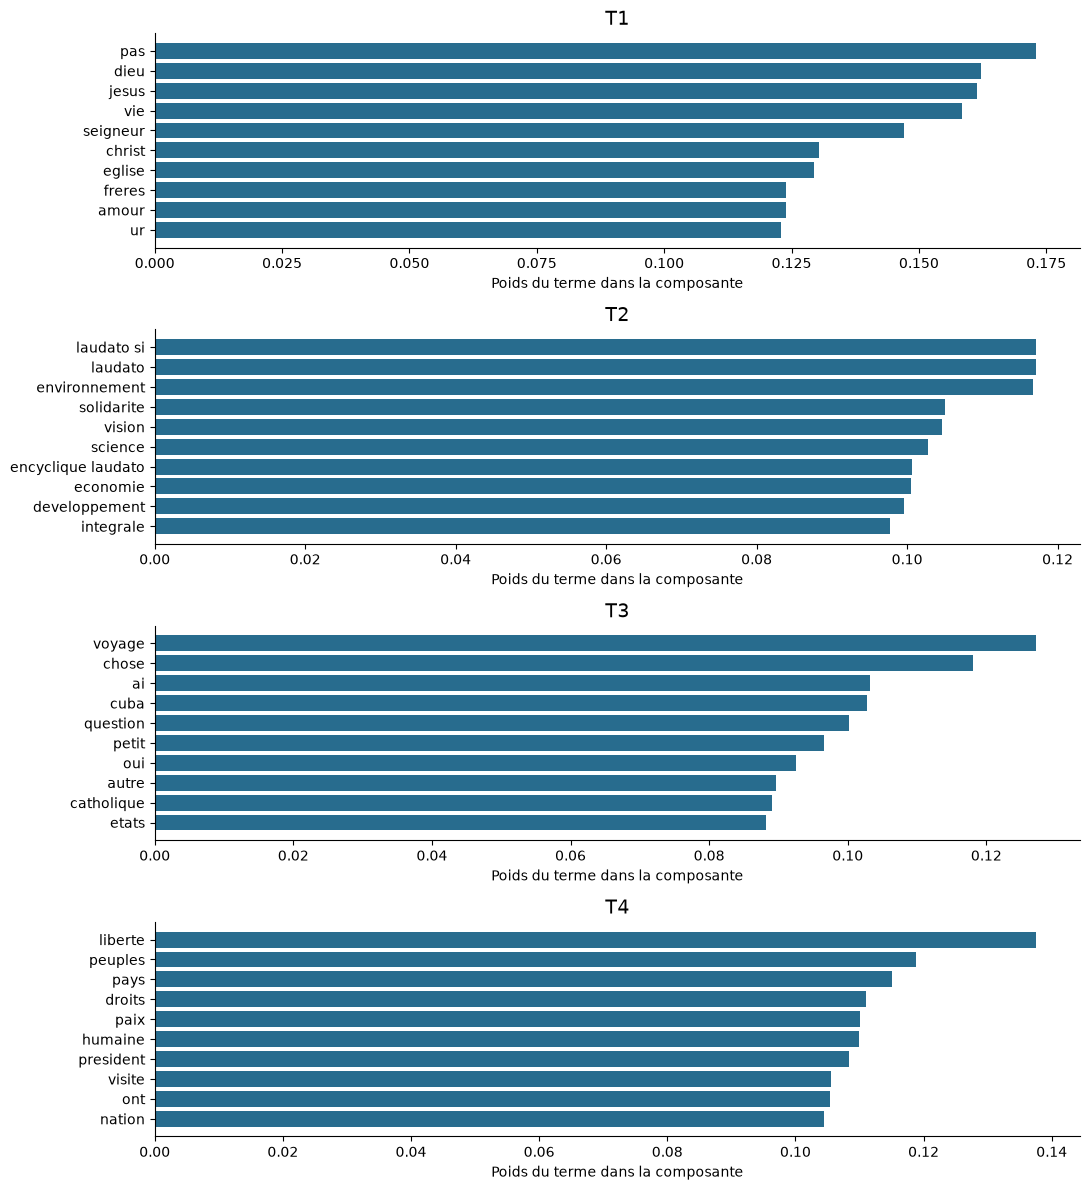

In [4]:
representants = []
for j, theme in enumerate(themes):
    for i in np.argsort(poids[:, j])[::-1][:3]:
        r = df.iloc[i]
        representants.append({"theme": theme, "poids_relatif": round(poids[i, j], 3),
                              "titre": r["title"], "lieu": r["lieu_analyse"],
                              "extrait": r["text"][:700], "source": r["source_url"]})
display(pd.DataFrame(representants))
fig, axes = plt.subplots(K, 1, figsize=(11, 3 * K), squeeze=False)
for j, ax in enumerate(axes.ravel()):
    inds = np.argsort(H[j])[-10:]
    ax.barh(vocab[inds], H[j, inds], color="#286c8e")
    ax.set_title(themes[j])
    ax.set_xlabel("Poids du terme dans la composante")
fig.tight_layout()
plt.show()

## Comparer les profils par lieu

Chaque discours compte autant, indépendamment de sa longueur. Les lieux avec moins de `MIN_DOCUMENTS` discours exploitables sont exclus du graphique mais restent dans les exports. Le corpus mêle publics et genres ; ne pas attribuer les différences au seul lieu.

,T1,T2,T3,T4,n_documents
lieu_analyse,,,,,
Inconnu,0.010321,0.000000,0.975092,0.014587,3
La Havane,0.257721,0.000000,0.335033,0.407246,2
New York,0.283290,0.075469,0.052797,0.588445,4
Philadelphie,0.646693,0.003084,0.024341,0.325882,6
Santiago de Cuba,0.866781,0.000000,0.110508,0.022711,1
Vatican (à vérifier),0.533946,0.237506,0.162598,0.065950,13
Washington,0.484895,0.043409,0.006774,0.464923,4


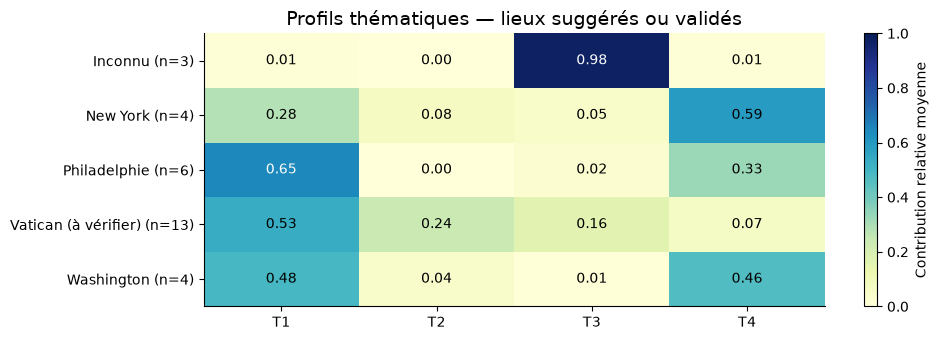

In [5]:
MIN_DOCUMENTS = 3
scores = pd.DataFrame(poids, columns=themes, index=df.index)
resultats = pd.concat([df[["event_id", "language", "date", "title", "lieu_analyse", "source_url"]], scores], axis=1)
resultats["sans_signal"] = sans_signal
valides = resultats.loc[~resultats["sans_signal"]]
effectifs = valides.groupby("lieu_analyse").size()
profils = valides.groupby("lieu_analyse")[themes].mean()
display(profils.join(effectifs.rename("n_documents")))
retenus = profils.loc[effectifs.ge(MIN_DOCUMENTS)]
if len(retenus):
    fig, ax = plt.subplots(figsize=(10, max(3, len(retenus) * .7)))
    im = ax.imshow(retenus, aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
    ax.set_xticks(range(K), themes)
    ax.set_yticks(range(len(retenus)), [f"{ville} (n={effectifs[ville]})" for ville in retenus.index])
    for i in range(len(retenus)):
        for j in range(K):
            ax.text(j, i, f"{retenus.iloc[i, j]:.2f}", ha="center", va="center",
                    color="white" if retenus.iloc[i, j] > .6 else "black")
    fig.colorbar(im, ax=ax, label="Contribution relative moyenne")
    ax.set_title("Profils thématiques — lieux suggérés ou validés")
    fig.tight_layout()
    fig.savefig(RESULTATS / "themes_par_lieu.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Pas de groupe suffisamment grand ; diminuer le seuil pour une exploration prudente.")
resultats.to_csv(RESULTATS / "themes_documents.csv", index=False, encoding="utf-8-sig")
table_themes.to_csv(RESULTATS / "themes_termes.csv", index=False, encoding="utf-8-sig")

## Recherche de discours similaires

Choisir `POSITION_REFERENCE` et retrouver les textes proches lexicalement. La similarité cosinus ne prouve pas une influence ou une reprise textuelle.

In [6]:
POSITION_REFERENCE = 0
similarites = cosine_similarity(X[POSITION_REFERENCE], X).ravel()
ordre = np.argsort(similarites)[::-1]
ordre = [i for i in ordre if i != POSITION_REFERENCE][:5]
print("Référence :", df.iloc[POSITION_REFERENCE]["title"])
proches = df.iloc[ordre][["title", "date", "lieu_analyse", "source_url"]].copy()
proches["similarite_cosinus"] = similarites[ordre]
display(proches)

Référence : Aux participants au chapitre général des prêtres de Schönstatt (3 septembre 2015)


,title,date,lieu_analyse,source_url,similarite_cosinus
19,Voyage apostolique - États-Unis d'Amérique : R...,2015-09-23,Washington,https://www.vatican.va/content/francesco/fr/sp...,0.257927
6,Aux participants au Chapitre général des Missi...,2015-09-11,Vatican (à vérifier),https://www.vatican.va/content/francesco/fr/sp...,0.236838
2,Aux prélats de la Conférence épiscopale du Por...,2015-09-07,Vatican (à vérifier),https://www.vatican.va/content/francesco/fr/sp...,0.224092
26,Voyage apostolique - États-Unis d'Amérique : F...,2015-09-26,Philadelphie,https://www.vatican.va/content/francesco/fr/sp...,0.219685
15,Voyage apostolique - Cuba : Salut aux jeunes d...,2015-09-20,La Havane,https://www.vatican.va/content/francesco/fr/sp...,0.218034


## Robustesse et interprétation

Réexécuter avec 3 puis 5 thèmes et avec `MASQUER_LIEUX=True`. Les thèmes peuvent se diviser ou fusionner ; leurs numéros ne sont pas directement comparables entre exécutions. Vérifier que les conclusions survivent à ces changements, à l'exclusion des entretiens et à l'équilibrage des lieux.

Sur un corpus étendu : comparer par année, contrôler le public et le genre, distinguer traductions et documents uniques, puis évaluer les thèmes sur une annotation humaine. Les exports sont écrasés lors de la réexécution ; archiver les configurations à comparer.

In [7]:
import sklearn
config = {"corpus": str(CORPUS.relative_to(ROOT)), "langue": LANGUE,
          "documents": len(df), "themes": K, "seed": SEED,
          "masquer_lieux": MASQUER_LIEUX, "sklearn_version": sklearn.__version__,
          "stopwords": STOPWORDS, "min_documents_par_lieu": MIN_DOCUMENTS}
(RESULTATS / "configuration_themes.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Exports :", RESULTATS)

Exports : C:\Users\arthr\Desktop\ENSAE 2A\S1\projet-discours\resultats
